# Project 26 — Card-Fraud Triage: GMM Density Scoring vs Autoencoder Anomaly Detector

**Team T068 · Section B** — Sharma Piyush (2401010437) · Saransh Singh Tomar (2401010418) · Satwik Mani Tripathi (2401020056) · Gourav Tanwar (2401010173) · Alok Kumar (2401010058)
## Notebook 04 — Phase 2 Hybrid Study: Combining Gaussian Densities (ML) with Autoencoders (DL)

**Why a hybrid?** Each phase has a clear weakness:

| Model | Strength | Gap |
|---|---|---|
| GMM on raw features (Phase 1) | full probabilistic density; whitens directions by their variance | fixed Gaussian component shape; hundreds of parameters per component ($d(d+3)/2$ in $d$ dimensions); EM local optima |
| Autoencoder (Phase 2) | learns a non-linear model of legitimate behaviour | one scalar score; weights all residual directions equally; can partly reconstruct fraud |

We test **four ways of combining them**. Each is technically motivated and comes from the literature, and each
isolates one idea:

| ID | Hybrid | Idea | Literature |
|---|---|---|---|
| H1 | **Latent GMM**: GMM on the AE code $\mathbf{z}$ | density estimation is easier in a low-dimensional learned space | DAGMM (Zong et al., 2018) |
| H2 | **DAGMM-style**: GMM on $[\mathbf{z},\ \log e,\ \cos(\mathbf{x},\hat{\mathbf{x}})]$ | combine *where* a point is on the manifold with *how far* it is from it | DAGMM |
| H3 | **Reconstruction-augmented GMM**: GMM on $[\mathbf{x},\ \log e]$ | keep the raw features (no information lost) and add the AE error as a learned extra dimension | DAGMM idea, without the encoder bottleneck |
| H4 | **Late fusion**: average of rank-normalised GMM and AE scores | naive ensemble baseline that any real hybrid must beat | ensemble practice |
| H5 | **Semi-supervised stacking**: gradient boosting on $[\mathbf{x}, \text{GMM score}, \text{AE error}]$ using the few frauds analysts have labelled | triage feedback loop: reviewed alerts become labels | Carcillo et al. (2021); Dal Pozzolo et al. (2018) |

**Leakage control.** The legitimate training rows are split at random into two halves. **Half A** trains the AE.
**Half B** (a random 40,000 of its rows, to keep the run Colab-sized) fits every stage-2 GMM, so the AE never scores
its own training data (its errors there would be unrealistically small). The plain GMM baseline is also fitted on half B, so H0–H4 see exactly the same rows. The
whole procedure is repeated for **3 seeds** (different halves and AE initialisations).

> **Runtime:** GPU recommended (T4); about 15–20 minutes.

## 0. Setup

In [1]:
# ============================================================
# Common setup — identical in every notebook of Project 26
# (data download, chronological split, features, metrics, plots)
# ============================================================
import os, sys, json, time, hashlib, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, RobustScaler, PowerTransformer, QuantileTransformer
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
IN_COLAB = "google.colab" in sys.modules

# ---------- paths ----------
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"  # public mirror of the ULB/Kaggle file
DATA_SHA256 = "76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89"
DATA_PATH = Path(os.environ.get("FRAUD_DATA", "creditcard.csv"))
OUT = Path(os.environ.get("FRAUD_OUT", "outputs"))
FIG, RES = OUT / "figures", OUT / "results"
FIG.mkdir(parents=True, exist_ok=True)
RES.mkdir(parents=True, exist_ok=True)

# ---------- plotting ----------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})
C_LEGIT, C_FRAUD = "#4C72B0", "#C44E52"


def savefig(name):
    """Save the current figure into outputs/figures (used by the IEEE report)."""
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")


def save_json(obj, name):
    def conv(o):
        if isinstance(o, dict):
            return {str(k): conv(v) for k, v in o.items()}
        if isinstance(o, (list, tuple)):
            return [conv(v) for v in o]
        if isinstance(o, np.generic):
            return o.item()
        return o
    (RES / name).write_text(json.dumps(conv(obj), indent=2))


# ---------- data ----------
def download_data(path=DATA_PATH):
    """Download the ULB credit-card dataset (once) and verify its checksum."""
    if not path.exists():
        print("Downloading dataset (~150 MB) ...")
        urllib.request.urlretrieve(DATA_URL, path)
    sha = hashlib.sha256(path.read_bytes()).hexdigest()
    assert sha == DATA_SHA256, "checksum mismatch - the file is not the original dataset"
    return path


def load_data():
    """Read the CSV, drop exact duplicate rows, order by Time."""
    df = pd.read_csv(download_data())
    info = {"rows_raw": len(df), "frauds_raw": int(df.Class.sum())}
    dup = df.duplicated(keep="first")
    info.update(duplicates_dropped=int(dup.sum()), fraud_duplicates_dropped=int(df.loc[dup, "Class"].sum()))
    df = df.loc[~dup].sort_values("Time", kind="stable").reset_index(drop=True)
    info.update(rows=len(df), frauds=int(df.Class.sum()))
    return df, info


def chronological_split(df, fractions=(0.6, 0.2, 0.2)):
    """Consecutive time blocks: train (past) -> validation -> test (future)."""
    n = len(df)
    a, b = int(round(fractions[0] * n)), int(round((fractions[0] + fractions[1]) * n))
    return df.iloc[:a].copy(), df.iloc[a:b].copy(), df.iloc[b:].copy()


# ---------- features ----------
V_COLS = [f"V{i}" for i in range(1, 29)]
FEATURE_SETS = {
    "pca": V_COLS,
    "pca+amount": V_COLS + ["log_amount"],
    "full": V_COLS + ["log_amount", "hour_sin", "hour_cos"],
}


def add_features(df):
    """log(1+Amount) and time-of-day on the unit circle; raw Time is dropped."""
    out = df.copy()
    out["log_amount"] = np.log1p(out["Amount"])
    out["hour"] = (out["Time"] % 86400) / 3600.0
    out["hour_sin"] = np.sin(2 * np.pi * out["hour"] / 24)
    out["hour_cos"] = np.cos(2 * np.pi * out["hour"] / 24)
    return out


def make_scaler(kind):
    return {
        "standard": StandardScaler(),
        "robust": RobustScaler(),
        "power": PowerTransformer(method="yeo-johnson", standardize=True),
        "quantile": QuantileTransformer(output_distribution="normal", n_quantiles=1000, subsample=200_000, random_state=SEED),
    }[kind]


class Preprocessor:
    """Select a feature set and scale it. Fitted on LEGITIMATE TRAINING rows only."""

    def __init__(self, feature_set="full", scaler="standard"):
        self.cols, self.kind = FEATURE_SETS[feature_set], scaler
        self.scaler = make_scaler(scaler)

    def fit(self, df_legit):
        assert df_legit["Class"].sum() == 0, "fit on legitimate rows only"
        self.scaler.fit(df_legit[self.cols])
        return self

    def transform(self, df):
        return self.scaler.transform(df[self.cols]).astype(np.float32)


# ---------- triage metrics (higher score = more suspicious) ----------
FPR_BUDGETS = (0.001, 0.005, 0.01)   # 0.1 %, 0.5 %, 1 % of legitimate customers wrongly flagged
CAPACITIES = (50, 100, 200, 500)       # alerts an analyst team can review


def pr_auc(y, s):
    return float(average_precision_score(y, s))


def threshold_at_fpr(y, s, fpr):
    """Smallest threshold whose false-positive rate on (y, s) is <= fpr."""
    neg = np.sort(np.asarray(s)[np.asarray(y) == 0])
    idx = min(max(int(np.ceil((1 - fpr) * len(neg))) - 1, 0), len(neg) - 1)
    return float(neg[idx])


def confusion_at(y, s, thr):
    y, flag = np.asarray(y), np.asarray(s) > thr
    tp, fp = int((flag & (y == 1)).sum()), int((flag & (y == 0)).sum())
    fn, tn = int((~flag & (y == 1)).sum()), int((~flag & (y == 0)).sum())
    return dict(threshold=float(thr), alerts=tp + fp, tp=tp, fp=fp, fn=fn, tn=tn,
                precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1), fpr=fp / max(fp + tn, 1))


def at_capacity(y, s, k):
    top = np.argsort(-np.asarray(s), kind="stable")[:k]
    tp = int(np.asarray(y)[top].sum())
    return dict(k=k, tp=tp, precision=tp / k, recall=tp / max(int(np.sum(y)), 1))


def bootstrap_ci(y, s, n_boot=1000, seed=SEED):
    """Stratified bootstrap 95 % interval for PR-AUC."""
    rng = np.random.default_rng(seed)
    y, s = np.asarray(y), np.asarray(s)
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    vals = [pr_auc(y[i], s[i]) for i in
            (np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(n_boot))]
    return [float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))]


def paired_bootstrap(y, s_a, s_b, n_boot=1000, seed=SEED):
    """PR-AUC(a) - PR-AUC(b) on identical resamples -> difference, 95 % CI, P(a <= b)."""
    rng = np.random.default_rng(seed)
    y, s_a, s_b = map(np.asarray, (y, s_a, s_b))
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    d = []
    for _ in range(n_boot):
        i = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        d.append(pr_auc(y[i], s_a[i]) - pr_auc(y[i], s_b[i]))
    d = np.asarray(d)
    return dict(diff=pr_auc(y, s_a) - pr_auc(y, s_b), ci=[float(np.quantile(d, .025)), float(np.quantile(d, .975))],
                p_not_better=float((d <= 0).mean()))


def evaluate(name, y_val, s_val, y_test, s_test, n_boot=1000):
    """Thresholds are chosen on VALIDATION, then applied unchanged to TEST."""
    r = dict(model=name, val_pr_auc=pr_auc(y_val, s_val), test_pr_auc=pr_auc(y_test, s_test),
             test_roc_auc=float(roc_auc_score(y_test, s_test)), test_pr_auc_ci=bootstrap_ci(y_test, s_test, n_boot),
             base_rate=float(np.mean(y_test)), budgets={}, capacity={})
    for f in FPR_BUDGETS:
        r["budgets"][f] = confusion_at(y_test, s_test, threshold_at_fpr(y_val, s_val, f))
    for k in CAPACITIES:
        r["capacity"][k] = at_capacity(y_test, s_test, k)
    return r


def summary_table(reports):
    rows = []
    for r in reports:
        row = {"model": r["model"], "val PR-AUC": r["val_pr_auc"], "test PR-AUC": r["test_pr_auc"],
               "95% CI": "[{:.3f}, {:.3f}]".format(*r["test_pr_auc_ci"]), "test ROC-AUC": r["test_roc_auc"]}
        for f, b in r["budgets"].items():
            row[f"Recall@FPR{float(f)*100:g}%"] = b["recall"]
            row[f"real FPR{float(f)*100:g}%"] = b["fpr"]
        for k, c in r["capacity"].items():
            row[f"P@{k}"] = c["precision"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")


def plot_pr_curves(y, scores, title, name=None, ax=None):
    """Precision-recall curves for several scorers on the same labels."""
    ax = ax or plt.subplots(figsize=(6.5, 4.8))[1]
    for label, s in scores.items():
        p, r, _ = precision_recall_curve(y, s)
        ax.plot(r, p, lw=1.8, label=f"{label} (AP={pr_auc(y, s):.3f})")
    ax.axhline(np.mean(y), ls="--", c="grey", lw=1, label=f"base rate = {np.mean(y):.4f}")
    ax.set(xlabel="Recall", ylabel="Precision", title=title, xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(fontsize=8, loc="upper right")
    if name:
        savefig(name)
    return ax


def finish_colab(zip_name):
    """On Colab: zip outputs/ and download it so figures/results can go into the repo."""
    if IN_COLAB:
        import shutil
        from google.colab import files
        shutil.make_archive(zip_name, "zip", OUT)
        files.download(f"{zip_name}.zip")
    else:
        print("Outputs saved in", OUT.resolve())
import copy
from dataclasses import dataclass, replace, asdict
import torch
import torch.nn as nn
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import HistGradientBoostingClassifier
from scipy.stats import rankdata, spearmanr

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
QUICK = os.environ.get("FRAUD_QUICK") == "1"
SEEDS = [0] if QUICK else [0, 1, 2]
print("device:", DEVICE, "| quick mode:", QUICK)

# Selected configurations from Notebook 02 (Phase 1) and Notebook 03 (Phase 2)
P1 = {'feature_set': 'pca', 'scaler': 'quantile', 'cov': 'full', 'k': 4}
P2 = {'scaler': 'standard', 'model': 'Denoising AE', 'cfg': {'hidden': (24, 16), 'latent': 16, 'act': 'elu', 'dropout': 0.0, 'noise': 0.2, 'mask': 0.0, 'wd': 1e-05}}   # autoencoder used as stage 1

device: cuda | quick mode: False


## 1. Autoencoder code (identical to Notebook 03)

In [2]:
ACTS = {"elu": nn.ELU, "relu": nn.ReLU, "tanh": nn.Tanh, "linear": nn.Identity}


class AutoEncoder(nn.Module):
    """Symmetric MLP autoencoder: d -> hidden... -> latent -> ...hidden -> d (linear output)."""

    def __init__(self, d, hidden=(24, 16), latent=8, act="elu", dropout=0.0):
        super().__init__()
        A = ACTS[act]
        enc, prev = [], d
        for h in hidden:
            enc += [nn.Linear(prev, h), A(), nn.Dropout(dropout)]
            prev = h
        enc.append(nn.Linear(prev, latent))
        dec, prev = [], latent
        for h in reversed(hidden):
            dec += [nn.Linear(prev, h), A(), nn.Dropout(dropout)]
            prev = h
        dec.append(nn.Linear(prev, d))
        self.encoder, self.decoder = nn.Sequential(*enc), nn.Sequential(*dec)

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z


@dataclass(frozen=True)
class Cfg:
    hidden: tuple = (24, 16)
    latent: int = 8
    act: str = "elu"
    dropout: float = 0.0
    noise: float = 0.0        # Gaussian input-noise std (denoising AE if > 0)
    mask: float = 0.0         # masking-noise probability (alternative corruption)
    wd: float = 1e-5          # L2 weight decay
    lr: float = 2e-3
    batch: int = 2048
    epochs: int = 3 if QUICK else 200
    patience: int = 10
    seed: int = 0


def corrupt(x, cfg):
    if cfg.noise > 0:
        x = x + cfg.noise * torch.randn_like(x)
    if cfg.mask > 0:
        x = x * (torch.rand_like(x) > cfg.mask)
    return x


def train_ae(X, cfg: Cfg):
    """Train on legitimate rows X. A random 10 % of X (label-free) drives early stopping."""
    torch.manual_seed(cfg.seed); np.random.seed(cfg.seed)
    idx = np.random.default_rng(cfg.seed).permutation(len(X))
    n_hold = len(X) // 10
    Xh = torch.tensor(X[idx[:n_hold]], device=DEVICE)
    Xt = torch.tensor(X[idx[n_hold:]], device=DEVICE)
    model = AutoEncoder(X.shape[1], cfg.hidden, cfg.latent, cfg.act, cfg.dropout).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.wd)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)
    g = torch.Generator(device="cpu").manual_seed(cfg.seed)
    best, best_state, wait, hist = np.inf, None, 0, []
    for ep in range(cfg.epochs):
        model.train()
        perm = torch.randperm(len(Xt), generator=g).to(DEVICE)
        tot = 0.0
        for i in range(0, len(Xt), cfg.batch):
            xb = Xt[perm[i:i + cfg.batch]]
            xhat, _ = model(corrupt(xb, cfg))
            loss = ((xhat - xb) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():
            hold = ((model(Xh)[0] - Xh) ** 2).mean().item()
        sched.step(hold)
        hist.append(dict(epoch=ep + 1, train_loss=tot / len(Xt), holdout_loss=hold))
        if hold < best - 1e-5:
            best, best_state, wait = hold, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= cfg.patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    model.hold_idx = idx[:n_hold]   # rows never used for gradient updates
    return model, pd.DataFrame(hist)


@torch.no_grad()
def recon(model, X, bs=65536):
    """Return reconstructions and latent codes for X (clean input, eval mode)."""
    xs, zs = [], []
    for i in range(0, len(X), bs):
        xb = torch.tensor(X[i:i + bs], device=DEVICE)
        xh, z = model(xb)
        xs.append(xh.cpu().numpy()); zs.append(z.cpu().numpy())
    return np.concatenate(xs), np.concatenate(zs)


def ae_score(model, X):
    """Anomaly score = mean squared reconstruction error per transaction."""
    xh, _ = recon(model, X)
    return ((X - xh) ** 2).mean(axis=1)

## 2. Data, inputs and the two single-paradigm models

In [3]:
df, info = load_data()
train, val, test = chronological_split(df)
train, val, test = add_features(train), add_features(val), add_features(test)
train_legit = train[train.Class == 0]
y_train, y_val, y_test = train.Class.values, val.Class.values, test.Class.values

pre_g = Preprocessor(P1["feature_set"], P1["scaler"]).fit(train_legit)        # GMM inputs (Phase 1)
pre_a = Preprocessor(P1["feature_set"], P2["scaler"]).fit(train_legit)        # AE inputs (Phase 2)
G_tr, G_v, G_te = pre_g.transform(train_legit), pre_g.transform(val), pre_g.transform(test)
A_tr, A_v, A_te = pre_a.transform(train_legit), pre_a.transform(val), pre_a.transform(test)
AE_CFG = Cfg(**P2["cfg"])
print("AE config:", AE_CFG, "| AE inputs:", P2["scaler"])


def fit_gmm(X, k, seed=SEED, n_init=1):
    return GaussianMixture(k, covariance_type="full", reg_covar=1e-4, max_iter=500, n_init=n_init,
                           init_params="k-means++", random_state=seed).fit(X)


gmm_full = fit_gmm(G_tr, P1["k"], n_init=5)
s_gmm = (-gmm_full.score_samples(G_v), -gmm_full.score_samples(G_te))
print(f"Phase-1 GMM (all legit train rows): val AP={pr_auc(y_val, s_gmm[0]):.3f} test AP={pr_auc(y_test, s_gmm[1]):.3f}")

AE config: Cfg(hidden=(24, 16), latent=16, act='elu', dropout=0.0, noise=0.2, mask=0.0, wd=1e-05, lr=0.002, batch=2048, epochs=200, patience=10, seed=0) | AE inputs: standard
Phase-1 GMM (all legit train rows): val AP=0.695 test AP=0.686


## 3. Stage-2 features

In [4]:
def ae_parts(model, X):
    """Latent code z, log reconstruction error, cosine(x, x_hat)."""
    xh, z = recon(model, X)
    err = ((X - xh) ** 2).mean(1)
    cos = (X * xh).sum(1) / (np.linalg.norm(X, axis=1) * np.linalg.norm(xh, axis=1) + 1e-8)
    return z, np.log(err + 1e-8), cos


def stage2_inputs(model, G, A):
    """Feature matrices for each hybrid, given GMM inputs G and AE inputs A of the same rows."""
    z, le, cos = ae_parts(model, A)
    return {"H0 GMM on x (same rows)": G, "H1 latent GMM [z]": z,
            "H2 DAGMM-style [z, log e, cos]": np.column_stack([z, le, cos]), "H3 augmented GMM [x, log e]": np.column_stack([G, le])}


def robust_rank(s, ref):
    """Empirical CDF of s w.r.t. legitimate reference scores (in [0, 1]) — puts any score on a common scale."""
    ref = np.sort(ref)
    return np.searchsorted(ref, s, side="right") / len(ref)

## 4. Unsupervised hybrids H0–H4 (3 seeds × stage-2 $K \in \{1,2,3,4\}$)
$K$ for every stage-2 GMM is chosen by **mean validation PR-AUC**, the same rule as Phase 1.

In [5]:
KS = [1, 3] if QUICK else [1, 2, 3, 4]
rows, keep = [], {}
for sd in SEEDS:
    t0 = time.time()
    rng_sd = np.random.default_rng(sd)
    half = rng_sd.random(len(A_tr)) < 0.5
    B = rng_sd.choice(np.flatnonzero(~half), 40_000, replace=False)   # stage-2 rows: 40k from half B
    ae, _ = train_ae(A_tr[half], replace(AE_CFG, seed=sd))          # stage 1 on half A
    H_B = stage2_inputs(ae, G_tr[B], A_tr[B])
    H_v, H_te = stage2_inputs(ae, G_v, A_v), stage2_inputs(ae, G_te, A_te)
    e_B, e_v, e_te = (np.exp(stage2_inputs(ae, g, a)["H3 augmented GMM [x, log e]"][:, -1]) for g, a in
                      [(G_tr[B], A_tr[B]), (G_v, A_v), (G_te, A_te)])
    rows.append(dict(seed=sd, model="AE alone (reconstruction error)", k=0, val_ap=pr_auc(y_val, e_v), test_ap=pr_auc(y_test, e_te)))
    for name in H_B:
        sc = StandardScaler().fit(H_B[name])
        for k in KS:
            g = fit_gmm(sc.transform(H_B[name]), k, seed=sd)
            sv, st = -g.score_samples(sc.transform(H_v[name])), -g.score_samples(sc.transform(H_te[name]))
            rows.append(dict(seed=sd, model=name, k=k, val_ap=pr_auc(y_val, sv), test_ap=pr_auc(y_test, st)))
            keep[(sd, name, k)] = (sv, st, -g.score_samples(sc.transform(H_B[name])))
    # H4: late fusion of the H0 GMM (K = Phase-1 K) and the AE error, each rank-normalised on half-B legit rows
    sv0, st0, sB0 = keep[(sd, "H0 GMM on x (same rows)", P1["k"] if P1["k"] in KS else KS[-1])]
    fv = robust_rank(sv0, sB0) + robust_rank(e_v, e_B)
    ft = robust_rank(st0, sB0) + robust_rank(e_te, e_B)
    rows.append(dict(seed=sd, model="H4 late fusion (rank avg)", k=0, val_ap=pr_auc(y_val, fv), test_ap=pr_auc(y_test, ft)))
    keep[(sd, "H4 late fusion (rank avg)", 0)] = (fv, ft, None)
    keep[(sd, "AE alone (reconstruction error)", 0)] = (e_v, e_te, e_B)
    if sd == SEEDS[0]:
        keep["H_te"], keep["ae"] = H_te, ae
    print(f"seed {sd}: {time.time()-t0:.0f}s")
runs = pd.DataFrame(rows)

seed 0: 50s
seed 1: 50s
seed 2: 45s


In [6]:
by_k = runs.groupby(["model", "k"]).agg(val_ap=("val_ap", "mean"), val_std=("val_ap", "std"),
                                        test_ap=("test_ap", "mean"), test_std=("test_ap", "std")).reset_index()
best = by_k.loc[by_k.groupby("model").val_ap.idxmax()].set_index("model")
gm = pd.DataFrame([dict(k=P1["k"], val_ap=pr_auc(y_val, s_gmm[0]), val_std=0.0, test_ap=pr_auc(y_test, s_gmm[1]), test_std=0.0)],
                  index=["Phase-1 GMM (all legit rows)"])
summary = pd.concat([best, gm]).sort_values("val_ap", ascending=False)
summary.round(4)

,k,val_ap,val_std,test_ap,test_std
Phase-1 GMM (all legit rows),4,0.6949,0.0000,0.6859,0.0000
H0 GMM on x (same rows),2,0.6884,0.0007,0.6973,0.0126
"H3 augmented GMM [x, log e]",2,0.6865,0.0018,0.6965,0.0134
H4 late fusion (rank avg),0,0.3423,0.1859,0.5235,0.1368
AE alone (reconstruction error),0,0.1629,0.1108,0.3251,0.1136
"H2 DAGMM-style [z, log e, cos]",3,0.0249,0.0020,0.0436,0.0061
H1 latent GMM [z],4,0.0077,0.0020,0.0116,0.0041


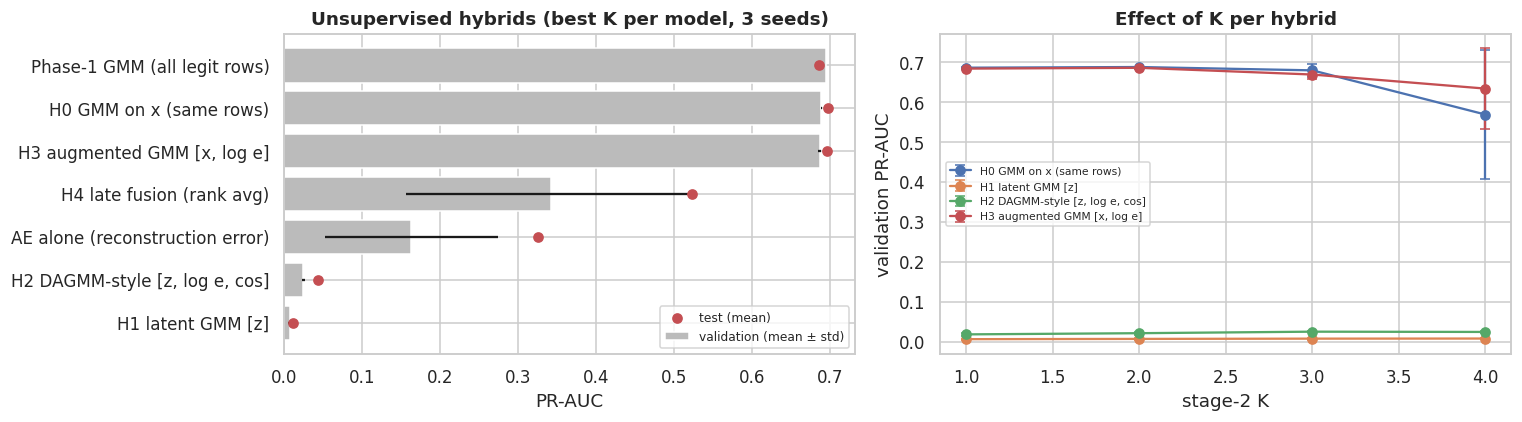

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
order = summary.index[::-1]
axes[0].barh(order, summary.loc[order, "val_ap"], xerr=summary.loc[order, "val_std"].fillna(0), color="#BBBBBB", label="validation (mean ± std)")
axes[0].scatter(summary.loc[order, "test_ap"], order, color=C_FRAUD, zorder=3, label="test (mean)")
axes[0].set(xlabel="PR-AUC", title="Unsupervised hybrids (best K per model, 3 seeds)"); axes[0].legend(fontsize=8)
for name in [n for n in by_k.model.unique() if n.startswith("H") and by_k[by_k.model == n].k.max() > 0]:
    s = by_k[by_k.model == name]
    axes[1].errorbar(s.k, s.val_ap, yerr=s.val_std, marker="o", capsize=3, label=name)
axes[1].set(xlabel="stage-2 K", ylabel="validation PR-AUC", title="Effect of K per hybrid"); axes[1].legend(fontsize=7)
plt.tight_layout(); savefig("04_hybrid_ablation"); plt.show()

**What the hybrid ablation shows** (mean over 3 seeds; each design at its best stage-2 K on validation):
* **H3, augmented GMM [x, log e] — ties the GMM, no gain.** It scores exactly as well as the plain GMM fitted on the
  same rows (H0): test ≈ 0.697 for both. Adding the autoencoder's error as an extra dimension gives the mixture
  nothing it does not already know. Notebook 03 showed why: on frauds the AE error and the GMM score are almost
  perfectly rank-correlated.
* **H4, late fusion — worse than the GMM alone.** The stage-1 autoencoder here is trained on only *half* the
  legitimate rows. Alone it is weak and unstable (test ≈ 0.33 ± 0.11, against ≈ 0.66 for the full-data DAE of
  Notebook 03), and averaging it in dilutes the GMM's ranking.
* **H1 and H2, latent-space hybrids (DAGMM idea) — fail completely** (test ≈ 0.01–0.04, near random). See §5.
* **Choice of K.** For the x-based hybrids the best stage-2 K is small (2), consistent with Phase 1.

## 5. Why do the latent-space hybrids (H1, H2) fail? Evidence
PR-AUC is decided at the **extreme top** of the ranking. So we ask, for each score, what share of test frauds lands
above the 99th percentile of legitimate test scores (i.e. would be flagged at a 1 % false-positive rate). We also
measure how strongly the AE error and the GMM score agree, separately on frauds and on legitimate rows.

In [8]:
sd0 = SEEDS[0]
k0 = P1["k"] if P1["k"] in KS else KS[-1]
kz = int(best.loc["H1 latent GMM [z]", "k"])


def top_share(s, q=0.99):
    return float(np.mean(s[y_test == 1] > np.quantile(s[y_test == 0], q)))


s_z, s_x, s_e = (keep[(sd0, "H1 latent GMM [z]", kz)][1], keep[(sd0, "H0 GMM on x (same rows)", k0)][1],
                 keep[(sd0, "AE alone (reconstruction error)", 0)][1])
z_te = keep["H_te"]["H1 latent GMM [z]"]
evidence = pd.DataFrame({
    "frauds above legit 99th pct — latent GMM on z (H1)": [top_share(s_z)],
    "frauds above legit 99th pct — GMM on x (H0)": [top_share(s_x)],
    "frauds above legit 99th pct — AE error": [top_share(s_e)],
    "mean |z| legit": [np.abs(z_te[y_test == 0]).mean()],
    "mean |z| fraud": [np.abs(z_te[y_test == 1]).mean()],
    "Spearman(AE error, GMM score) — test frauds": [spearmanr(s_e[y_test == 1], s_gmm[1][y_test == 1]).statistic],
    "Spearman(AE error, GMM score) — test legit": [spearmanr(s_e[y_test == 0], s_gmm[1][y_test == 0]).statistic],
}).T.rename(columns={0: "value"})
evidence.round(3)

,value
frauds above legit 99th pct — latent GMM on z (H1),0.041
frauds above legit 99th pct — GMM on x (H0),0.770
frauds above legit 99th pct — AE error,0.770
mean |z| legit,2.908
mean |z| fraud,3.524
"Spearman(AE error, GMM score) — test frauds",0.952
"Spearman(AE error, GMM score) — test legit",0.384


**Where the anomaly information lives.**
* **The latent code throws it away.** At a 1 % false-positive rate, the latent GMM (H1) flags only ≈ 4 % of test
  frauds, while the GMM on raw inputs and the AE error each flag ≈ 77 %. Frauds' codes are barely larger than
  legitimate ones (mean |z| ≈ 3.5 vs ≈ 2.9).
* **Why.** The encoder is trained only on legitimate data, so it maps *any* input, fraud included, close to the region
  of normal codes. It is a many-to-one, contractive map. What betrays a fraud is that the decoder cannot rebuild it
  from that normal-looking code: the evidence sits in the **reconstruction residual**, not in the code.
* **This is why DAGMM-style designs fail here.** They model the density of the code, which carries almost no fraud
  signal on this data.
* **Agreement with the GMM.** On test frauds the AE error and the GMM score agree almost perfectly (ρ ≈ 0.95). On
  legitimate rows they agree much less (ρ ≈ 0.38): they flag *different* legitimate customers, but they find the
  *same* frauds. So combining them cannot catch new frauds; it can only reshuffle false alarms, which H3/H4 show does
  not help.

## 6. H5 — Semi-supervised stacking: what are a few analyst labels worth?
In deployment, analysts review the top alerts and their verdicts become labels. H5 trains a gradient-boosting
classifier on the **training block** with only $n$ labelled frauds (random subsets, 5 draws each). It compares two
feature sets:
* raw features only;
* raw features + the GMM score + the AE error (the hybrid).

To avoid leakage, GMM/AE scores for legitimate training rows are computed **out-of-fold**: 2-fold cross-fitting, where
each half is scored by models fitted on the other half. The horizontal line is the label-free GMM.

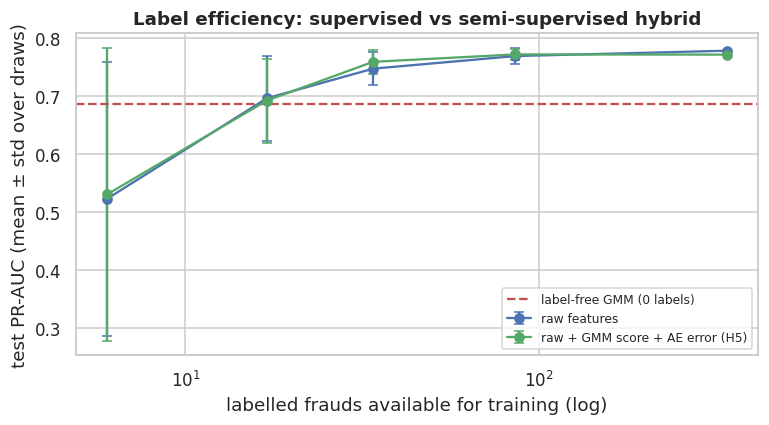

,labelled_frauds,features,val_ap,val_std,test_ap,test_std
0,6,raw + GMM score + AE error (H5),0.547,0.262,0.531,0.252
1,6,raw features,0.549,0.256,0.523,0.236
2,17,raw + GMM score + AE error (H5),0.671,0.088,0.692,0.072
3,17,raw features,0.687,0.082,0.696,0.073
4,34,raw + GMM score + AE error (H5),0.715,0.019,0.759,0.021
5,34,raw features,0.718,0.020,0.747,0.029
6,86,raw + GMM score + AE error (H5),0.762,0.016,0.772,0.009
7,86,raw features,0.765,0.025,0.769,0.013
8,342,raw + GMM score + AE error (H5),0.734,NaN,0.771,NaN
9,342,raw features,0.743,NaN,0.778,NaN


In [9]:
fold = np.random.default_rng(SEED).integers(0, 2, len(train))
legit_tr = y_train == 0
G_all, A_all = pre_g.transform(train), pre_a.transform(train)
oof_g, oof_e = np.zeros(len(train)), np.zeros(len(train))
v_g, t_g, v_e, t_e = np.zeros(len(val)), np.zeros(len(test)), np.zeros(len(val)), np.zeros(len(test))
for f in [0, 1]:
    fit_rows = legit_tr & (fold != f)
    g = fit_gmm(G_all[fit_rows], P1["k"], seed=f, n_init=3)
    m, _ = train_ae(A_all[fit_rows], replace(AE_CFG, seed=f))
    own = legit_tr & (fold == f)
    oof_g[own], oof_e[own] = -g.score_samples(G_all[own]), ae_score(m, A_all[own])
    fr = ~legit_tr                                     # frauds were never fitted on: average both fold models
    oof_g[fr] += -g.score_samples(G_all[fr]) / 2; oof_e[fr] += ae_score(m, A_all[fr]) / 2
    v_g += -g.score_samples(G_v) / 2; t_g += -g.score_samples(G_te) / 2
    v_e += ae_score(m, A_v) / 2; t_e += ae_score(m, A_te) / 2
shift = oof_g[legit_tr].min() - 1
FE = {"raw features": (G_all, G_v, G_te),
      "raw + GMM score + AE error (H5)": tuple(np.column_stack([G, np.log(s - shift), np.log(e)]) for G, s, e in
                                               [(G_all, oof_g, oof_e), (G_v, v_g, v_e), (G_te, t_g, t_e)])}
fr_idx = np.flatnonzero(y_train == 1)
budgets = [6, len(fr_idx)] if QUICK else [6, 17, 34, 86, len(fr_idx)]
semi = []
for n_lab in budgets:
    for draw in range(1 if n_lab == len(fr_idx) or QUICK else 5):
        keep_fr = np.random.default_rng(100 + draw).choice(fr_idx, n_lab, replace=False)
        idx = legit_tr.copy(); idx[keep_fr] = True
        for fname, (Xa, Xv_, Xt_) in FE.items():
            clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0,
                                                 random_state=draw).fit(Xa[idx], y_train[idx])
            semi.append(dict(labelled_frauds=n_lab, draw=draw, features=fname, val_ap=pr_auc(y_val, clf.predict_proba(Xv_)[:, 1]),
                             test_ap=pr_auc(y_test, clf.predict_proba(Xt_)[:, 1])))
            if n_lab == len(fr_idx):
                keep[("semi", fname)] = (clf.predict_proba(Xv_)[:, 1], clf.predict_proba(Xt_)[:, 1])
semi = pd.DataFrame(semi)
semi_sum = semi.groupby(["labelled_frauds", "features"]).agg(val_ap=("val_ap", "mean"), val_std=("val_ap", "std"),
                                                               test_ap=("test_ap", "mean"), test_std=("test_ap", "std")).reset_index()

fig, ax = plt.subplots(figsize=(8, 3.8))
for fname, c in zip(FE, ["#4C72B0", "#55A868"]):
    s = semi_sum[semi_sum.features == fname]
    ax.errorbar(s.labelled_frauds, s.test_ap, yerr=s.test_std.fillna(0), marker="o", capsize=3, color=c, label=fname)
ax.axhline(pr_auc(y_test, s_gmm[1]), color=C_FRAUD, ls="--", label="label-free GMM (0 labels)")
ax.set(xscale="log", xlabel="labelled frauds available for training (log)", ylabel="test PR-AUC (mean ± std over draws)",
       title="Label efficiency: supervised vs semi-supervised hybrid")
ax.legend(fontsize=8); savefig("04_label_efficiency"); plt.show()
semi_sum.round(3)

**What a few labels are worth.**
* **The label-free GMM is worth about 17 labelled frauds.** With 6 labelled frauds a supervised model is worse and
  very unstable (≈ 0.52 ± 0.24). With ≈ 17 it matches the label-free GMM (≈ 0.69). With ≥ 34 it clearly beats it
  (≈ 0.75–0.78).
* **H5 adds nothing measurable.** Adding the GMM score and the AE error as features gives the same PR-AUC as the raw
  features at every label budget (differences ≤ 0.01, far inside the spread). Gradient boosting already learns the
  relevant non-linear structure from the raw features.
* **Practical reading.** Start with the label-free GMM on day one. Once analysts have confirmed a few dozen frauds, a
  supervised model becomes the better ranker.

## 7. Final comparison on the test set (thresholds from validation)
* Label-free models: the Phase-1 GMM, the Phase-2 AE, and the best unsupervised hybrid (chosen on validation).
  Hybrid and AE scores are averaged over the 3 seeds.
* Label-using models (all 342 training frauds): the supervised reference and the semi-supervised hybrid H5.

In [10]:
def seed_avg(name, k):
    return tuple(np.mean([keep[(s, name, k)][i] for s in SEEDS], 0) for i in (0, 1))

hyb_names = [n for n in best.index if n.startswith(("H1", "H2", "H3", "H4"))]
best_hyb = max(hyb_names, key=lambda n: best.loc[n, "val_ap"])
final_scores = {
    "GMM (Phase 1)": s_gmm,
    "Autoencoder (Phase 2)": seed_avg("AE alone (reconstruction error)", 0),
    f"Best unsupervised hybrid: {best_hyb}": seed_avg(best_hyb, int(best.loc[best_hyb, "k"])),
    "Supervised GBM, raw features (uses labels)": keep[("semi", "raw features")],
    "Semi-supervised hybrid H5 (uses labels)": keep[("semi", "raw + GMM score + AE error (H5)")],
}
reports = [evaluate(n, y_val, sv, y_test, st) for n, (sv, st) in final_scores.items()]
table = summary_table(reports)
table.round(3)

,val PR-AUC,test PR-AUC,95% CI,test ROC-AUC,Recall@FPR0.1%,real FPR0.1%,Recall@FPR0.5%,real FPR0.5%,Recall@FPR1%,real FPR1%,P@50,P@100,P@200,P@500
model,,,,,,,,,,,,,,
GMM (Phase 1),0.695,0.686,"[0.572, 0.808]",0.934,0.757,0.001,0.784,0.003,0.784,0.006,0.90,0.56,0.285,0.116
Autoencoder (Phase 2),0.124,0.301,"[0.236, 0.402]",0.943,0.189,0.000,0.716,0.002,0.770,0.005,0.48,0.40,0.280,0.120
"Best unsupervised hybrid: H3 augmented GMM [x, log e]",0.687,0.695,"[0.586, 0.807]",0.961,0.757,0.001,0.757,0.003,0.770,0.006,0.92,0.56,0.280,0.116
"Supervised GBM, raw features (uses labels)",0.743,0.778,"[0.686, 0.861]",0.976,0.784,0.001,0.838,0.004,0.865,0.008,0.96,0.58,0.305,0.128
Semi-supervised hybrid H5 (uses labels),0.734,0.771,"[0.683, 0.855]",0.978,0.757,0.001,0.811,0.004,0.865,0.008,0.94,0.56,0.295,0.126


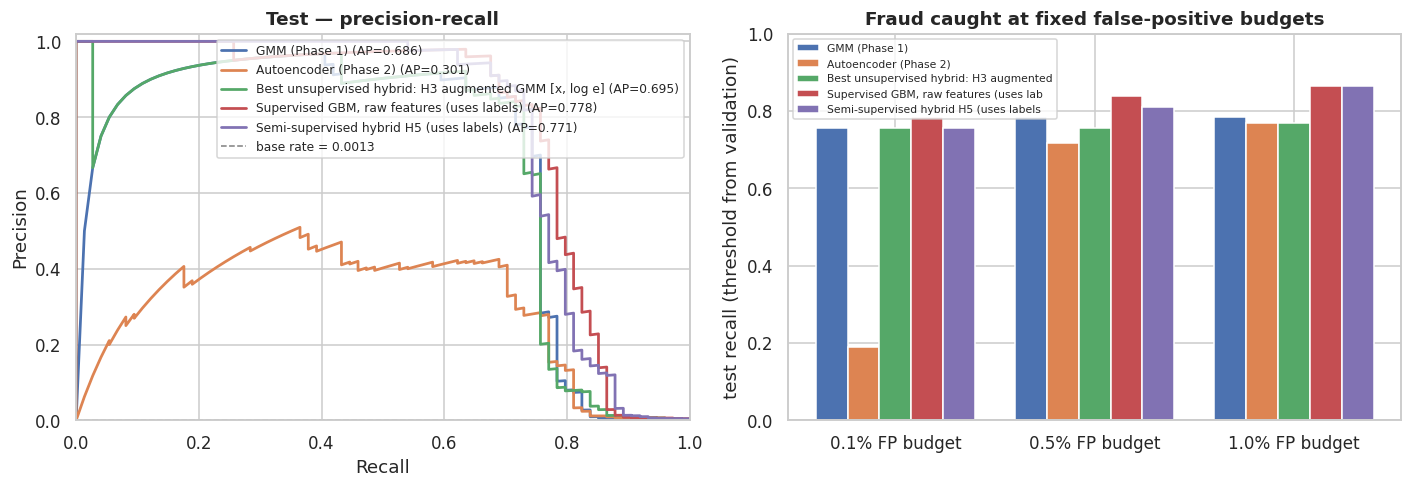

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
plot_pr_curves(y_test, {k: v[1] for k, v in final_scores.items()}, "Test — precision-recall", ax=axes[0])
x = np.arange(len(FPR_BUDGETS)); w = 0.16
for i, r in enumerate(reports):
    axes[1].bar(x + (i - 2) * w, [r["budgets"][f]["recall"] for f in FPR_BUDGETS], w, label=r["model"][:38])
axes[1].set_xticks(x); axes[1].set_xticklabels([f"{f:.1%} FP budget" for f in FPR_BUDGETS])
axes[1].set(ylabel="test recall (threshold from validation)", title="Fraud caught at fixed false-positive budgets", ylim=(0, 1))
axes[1].legend(fontsize=7)
plt.tight_layout(); savefig("04_final_comparison"); plt.show()

In [12]:
names = list(final_scores)
sig = {
    f"{names[2]} − GMM": paired_bootstrap(y_test, final_scores[names[2]][1], s_gmm[1]),
    "AE − GMM": paired_bootstrap(y_test, final_scores[names[1]][1], s_gmm[1]),
    "H5 − supervised GBM": paired_bootstrap(y_test, final_scores[names[4]][1], final_scores[names[3]][1]),
    "supervised GBM − GMM": paired_bootstrap(y_test, final_scores[names[3]][1], s_gmm[1]),
}
pd.DataFrame(sig).T

,diff,ci,p_not_better
"Best unsupervised hybrid: H3 augmented GMM [x, log e] − GMM",0.009082,"[-0.009487170248056917, 0.022984263858626914]",0.325
AE − GMM,-0.384439,"[-0.47368283768798514, -0.2992120530095749]",1.0
H5 − supervised GBM,-0.006752,"[-0.04522617551940121, 0.033498919387603764]",0.647
supervised GBM − GMM,0.092271,"[0.026022838561606077, 0.14468869980636376]",0.001


**Final comparison** (test set, thresholds from validation; the "Autoencoder" row is the stage-1 network trained on
half the legitimate rows; the full-data DAE of Notebook 03 scores 0.661):
* **No unsupervised hybrid beats the Phase-1 GMM.** The best one (H3) is +0.009 PR-AUC, 95 % CI [−0.009, +0.023],
  which is not significant.
* **Labels are what move the needle.** Supervised gradient boosting with all 342 training frauds beats the label-free
  GMM by +0.092 (CI [+0.026, +0.145], significant). The semi-supervised hybrid H5 is no better than supervised alone
  (−0.007, CI [−0.045, +0.033]).
* **The GMM stays the best label-free choice.** At the strict 0.1 % budget the GMM and H3 both catch 76 % of frauds
  with a top-50 queue that is ≈ 90 % fraud.

## 8. Triage recommendation: operating points of the recommended label-free system

In [13]:
label_free = [r for r in reports if "uses labels" not in r["model"]]
rb = max(label_free, key=lambda r: r["val_pr_auc"])
hours = (test.Time.max() - test.Time.min()) / 3600
op = []
for f, b in rb["budgets"].items():
    op.append({"policy": f"FP budget {float(f):.1%} (threshold from val)", "alerts": b["alerts"], "alerts/hour": round(b["alerts"] / hours, 1),
               "fraud caught": f"{b['tp']}/{b['tp']+b['fn']}", "recall": round(b["recall"], 3), "precision": round(b["precision"], 3),
               "legit customers flagged": b["fp"]})
for k, c in rb["capacity"].items():
    op.append({"policy": f"review capacity top-{k}", "alerts": int(k), "alerts/hour": round(int(k) / hours, 1),
               "fraud caught": f"{c['tp']}/{int(y_test.sum())}", "recall": round(c["recall"], 3), "precision": round(c["precision"], 3),
               "legit customers flagged": int(k) - c["tp"]})
print(f"Recommended label-free model (best validation PR-AUC): {rb['model']} | test window {hours:.1f} h | base rate {y_test.mean():.4%}")
pd.DataFrame(op)

Recommended label-free model (best validation PR-AUC): GMM (Phase 1) | test window 7.7 h | base rate 0.1304%


,policy,alerts,alerts/hour,fraud caught,recall,precision,legit customers flagged
0,FP budget 0.1% (threshold from val),94,12.3,56/74,0.757,0.596,38
1,FP budget 0.5% (threshold from val),221,28.9,58/74,0.784,0.262,163
2,FP budget 1.0% (threshold from val),399,52.1,58/74,0.784,0.145,341
3,review capacity top-50,50,6.5,45/74,0.608,0.900,5
4,review capacity top-100,100,13.1,56/74,0.757,0.560,44
5,review capacity top-200,200,26.1,57/74,0.770,0.285,143
6,review capacity top-500,500,65.3,58/74,0.784,0.116,442


## 9. Conclusions
1. **Hybrid designs were implemented with leakage-free two-stage fitting and ablated component by component.** None
   significantly improves on the Gaussian density of Phase 1. The best (H3, GMM on [x, log reconstruction error])
   *ties* it.
2. **The reason is measurable.** The autoencoder and the GMM find the *same* frauds (ρ ≈ 0.95 on fraud). The AE's
   latent code discards the anomaly information, which lives in the reconstruction residual. So DAGMM-style latent
   densities fail on this data.
3. **Labels matter more than model combinations.** The label-free GMM equals a supervised model trained on ~17
   labelled frauds. With all labels, supervised boosting is significantly better, and adding unsupervised scores (H5)
   does not help further.
4. **Recommendation for triage.** Deploy the label-free GMM first (simplest, stable, best on validation), with a
   threshold set by the review budget. Switch to, or add, a supervised model once a few dozen frauds have been
   confirmed. Retrain both regularly as fraud patterns drift.

**Future work.** Joint (end-to-end) DAGMM training; scoring the residual vector instead of the latent code with a
flexible density (e.g. a normalising flow); longer data with real drift; cost-sensitive thresholds using
transaction amounts.

In [14]:
out = dict(p1=P1, p2=P2, runs=runs.to_dict("records"), by_k=by_k.to_dict("records"), summary=summary.reset_index().to_dict("records"),
           evidence=evidence["value"].to_dict(), semi=semi_sum.to_dict("records"), reports=reports, significance=sig,
           best_hybrid=best_hyb, recommended=rb["model"], operating_points=op)
save_json(out, "04_hybrid_results.json")
display(table.round(3))
finish_colab("outputs_04_hybrid")

,val PR-AUC,test PR-AUC,95% CI,test ROC-AUC,Recall@FPR0.1%,real FPR0.1%,Recall@FPR0.5%,real FPR0.5%,Recall@FPR1%,real FPR1%,P@50,P@100,P@200,P@500
model,,,,,,,,,,,,,,
GMM (Phase 1),0.695,0.686,"[0.572, 0.808]",0.934,0.757,0.001,0.784,0.003,0.784,0.006,0.90,0.56,0.285,0.116
Autoencoder (Phase 2),0.124,0.301,"[0.236, 0.402]",0.943,0.189,0.000,0.716,0.002,0.770,0.005,0.48,0.40,0.280,0.120
"Best unsupervised hybrid: H3 augmented GMM [x, log e]",0.687,0.695,"[0.586, 0.807]",0.961,0.757,0.001,0.757,0.003,0.770,0.006,0.92,0.56,0.280,0.116
"Supervised GBM, raw features (uses labels)",0.743,0.778,"[0.686, 0.861]",0.976,0.784,0.001,0.838,0.004,0.865,0.008,0.96,0.58,0.305,0.128
Semi-supervised hybrid H5 (uses labels),0.734,0.771,"[0.683, 0.855]",0.978,0.757,0.001,0.811,0.004,0.865,0.008,0.94,0.56,0.295,0.126


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>